# Optimisation du Meilleur Modèle

Ce notebook effectue l'optimisation des hyperparamètres du meilleur modèle identifié lors de la phase de comparaison, en utilisant l'optimisation bayésienne.

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, 
    roc_auc_score, roc_curve, 
    accuracy_score, precision_score, recall_score, f1_score,
    make_scorer
)
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical, Real
import pickle
import time

## 2. Chargement des données

Cette étape consiste à importer le fichier de données préparées et à organiser la structure de travail. Le programme sépare le jeu de données en deux parties : d'un côté les caractéristiques (les 45 variables explicatives des employés) et de l'autre la cible (la colonne "Attrition" à prédire). Les fonctions d'affichage permettent de confirmer la volumétrie du projet (4 410 entrées) et d'observer la répartition réelle des classes, où l'on dénombre 3 699 employés restés en poste contre 711 ayant quitté l'entreprise.

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 45)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


## 3. Séparation des données

Cette étape prépare l'évaluation du modèle Random Forest en scindant les données en deux ensembles distincts : l'entraînement (70 %) et le test (30 %). L'utilisation de la stratification garantit que la proportion réelle entre les départs et les employés restés est rigoureusement conservée dans les deux groupes. Cette répartition permet de fournir 3 528 exemples à l'algorithme pour qu'il construise ses arbres de décision, tout en gardant 882 individus "inconnus" pour valider la fiabilité de ses prédictions finales.

In [3]:
# Séparation train/test (80/20 pour l'optimisation)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3528
Taille ensemble de test: 882


## 4. Chargement du résumé de comparaison

Cette étape consiste à identifier le modèle le plus performant avant d'entamer son optimisation. Le programme récupère les résultats d'une comparaison préalable stockée dans un fichier externe pour confirmer que le Random Forest est bien l'algorithme le plus efficace. L'affichage des métriques de base (comme l'Accuracy à 98,34 % ou le F1 Score à 0,94) fournit un point de comparaison précis : ces scores servent de "socle" de référence pour mesurer concrètement les gains de performance que l'optimisation apportera par la suite.

In [4]:
# Charger le résumé de comparaison
try:
    with open('Data/model_comparison_summary.pkl', 'rb') as f:
        comparison_summary = pickle.load(f)
    
    best_model_name = comparison_summary['best_model']
    print(f"Meilleur modèle identifié : {best_model_name}")
    print(f"\nMétriques du modèle de base :")
    for key, value in comparison_summary['best_model_metrics'].items():
        if key != 'Model':
            print(f"  {key:12s}: {value:.4f}")
except FileNotFoundError:
    print("⚠ Fichier de comparaison non trouvé. Nous utiliserons Random Forest par défaut.")
    best_model_name = "Random Forest"

Meilleur modèle identifié : Random Forest

Métriques du modèle de base :
  Accuracy    : 0.9834
  Precision   : 1.0000
  Recall      : 0.8942
  F1 Score    : 0.9442
  AUC-ROC     : 0.9949


## 5. Définition de l'espace de recherche des hyperparamètres

Cette étape définit le cadre de l'optimisation bayésienne en listant les leviers sur lesquels le programme peut agir pour améliorer le Random Forest. On établit des plages de valeurs précises (les hyperparamètres) pour contrôler la structure du modèle, comme le nombre d'arbres à construire ou leur profondeur maximale. Contrairement à un réglage manuel, cet espace de recherche permet à l'algorithme d'explorer intelligemment différentes combinaisons techniques (échantillonnage, division des nœuds, etc.) afin de trouver la configuration la plus efficace pour vos données.

In [5]:
# Espace de recherche des hyperparamètres pour Random Forest
param_space = {
    "n_estimators": Integer(50, 500),  # Nombre d'arbres
    "max_depth": Integer(5, 50),  # Profondeur maximale des arbres
    "min_samples_split": Integer(2, 20),  # Minimum d'échantillons pour diviser un nœud
    "min_samples_leaf": Integer(1, 10),  # Minimum d'échantillons dans une feuille
    "max_features": Categorical(["sqrt", "log2", None]),  # Nombre de features à utiliser
    "bootstrap": Categorical([True, False])  # Bootstrap activé/désactivé
}

print("Espace de recherche défini :")
for param, space in param_space.items():
    print(f"  {param:20s}: {space}")

Espace de recherche défini :
  n_estimators        : Integer(low=50, high=500, prior='uniform', transform='identity')
  max_depth           : Integer(low=5, high=50, prior='uniform', transform='identity')
  min_samples_split   : Integer(low=2, high=20, prior='uniform', transform='identity')
  min_samples_leaf    : Integer(low=1, high=10, prior='uniform', transform='identity')
  max_features        : Categorical(categories=('sqrt', 'log2', None), prior=None)
  bootstrap           : Categorical(categories=(True, False), prior=None)


## 6. Optimisation bayésienne - Accuracy

Cette phase lance l'ajustement automatique du Random Forest en utilisant l'Accuracy comme indicateur de réussite. Contrairement à une recherche aléatoire, l'optimisation bayésienne apprend de chaque essai précédent pour tester les combinaisons d'hyperparamètres les plus prometteuses dans l'espace défini. Le processus utilise une validation croisée (5-fold), ce qui signifie que chaque configuration est testée cinq fois sur des portions de données différentes pour garantir la robustesse des résultats. Après environ 13 minutes de calculs, le programme identifie la structure optimale, notamment un ensemble de 395 arbres d'une profondeur de 50, permettant d'atteindre un score de fiabilité de 98,21 % sur les données d'entraînement.

In [6]:
# Créer le modèle de base
rf = RandomForestClassifier(random_state=42)

# Optimisation bayésienne avec Accuracy
print("Début de l'optimisation bayésienne avec Accuracy...")
start_time = time.time()

opt_accuracy = BayesSearchCV(
    rf,
    param_space,
    n_iter=30,  # Nombre d'itérations pour l'optimisation
    cv=5,  # Validation croisée à 5 folds
    scoring="accuracy",  # Score basé sur l'accuracy
    n_jobs=1,  # Utilisation d'un seul cœur
    random_state=42,
    verbose=1
)

opt_accuracy.fit(X_train, y_train)

optimization_time_accuracy = time.time() - start_time

print(f"\nOptimisation terminée en {optimization_time_accuracy:.2f} secondes")
print(f"\nMeilleurs hyperparamètres (Accuracy) : {opt_accuracy.best_params_}")
print(f"Meilleur score CV (Accuracy) : {opt_accuracy.best_score_:.4f}")

Début de l'optimisation bayésienne avec Accuracy...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitt

c:\Users\Agordien\Documents\PRIVATE\CESI\2025-2026\IA\ARtificialIntelligence\Project\Projet\env\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.False_, np.int64(50), np.str_('log2'), np.int64(1), np.int64(2), np.int64(500)] before, using random point [True, np.int64(38), 'sqrt', np.int64(4), np.int64(18), np.int64(137)]
  warnings.warn(


Fitting 5 folds for each of 1 candidates, totalling 5 fits


c:\Users\Agordien\Documents\PRIVATE\CESI\2025-2026\IA\ARtificialIntelligence\Project\Projet\env\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.False_, np.int64(50), np.str_('log2'), np.int64(1), np.int64(2), np.int64(500)] before, using random point [True, np.int64(42), 'log2', np.int64(5), np.int64(12), np.int64(271)]
  warnings.warn(


Fitting 5 folds for each of 1 candidates, totalling 5 fits


c:\Users\Agordien\Documents\PRIVATE\CESI\2025-2026\IA\ARtificialIntelligence\Project\Projet\env\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.False_, np.int64(50), np.str_('log2'), np.int64(1), np.int64(2), np.int64(500)] before, using random point [True, np.int64(19), 'log2', np.int64(9), np.int64(6), np.int64(304)]
  warnings.warn(


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits

Optimisation terminée en 807.59 secondes

Meilleurs hyperparamètres (Accuracy) : OrderedDict([('bootstrap', False), ('max_depth', 50), ('max_features', 'log2'), ('min_samples_leaf', 1), ('min_samples_split', 2), ('n_estimators', 395)])
Meilleur score CV (Accuracy) : 0.9821


Une fois la configuration optimale trouvée, le modèle est confronté à l'ensemble de test, c'est-à-dire aux données qu'il n'a jamais rencontrées durant son entraînement. Le programme calcule ici plusieurs indicateurs clés pour valider la fiabilité réelle du Random Forest : l'Accuracy atteint un score exceptionnel de 99,66 %, tandis que la Précision de 100 % indique que chaque départ prédit par le modèle est correct. Le Recall à 97,89 % confirme que l'algorithme parvient désormais à identifier la quasi-totalité des cas d'attrition réels, validant ainsi l'efficacité de l'optimisation par rapport au modèle de base.

In [7]:
# Évaluer le modèle optimisé (Accuracy) sur le test set
best_model_accuracy = opt_accuracy.best_estimator_
y_pred_accuracy = best_model_accuracy.predict(X_test)
y_proba_accuracy = best_model_accuracy.predict_proba(X_test)[:, 1]

print("\n=== PERFORMANCES - Modèle optimisé (Accuracy) ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_accuracy):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_accuracy):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_accuracy):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_accuracy):.4f}")
print(f"AUC-ROC   : {roc_auc_score(y_test, y_proba_accuracy):.4f}")


=== PERFORMANCES - Modèle optimisé (Accuracy) ===
Accuracy  : 0.9966
Precision : 1.0000
Recall    : 0.9789
F1 Score  : 0.9893
AUC-ROC   : 0.9994


## 7. Optimisation bayésienne - F1 Score

Cette seconde phase d'optimisation bascule l'objectif du programme vers le F1 Score, une métrique qui cherche le compromis idéal entre la détection des départs (Recall) et la fiabilité de ces prédictions (Précision). Le processus, nettement plus intensif avec plus de 36 minutes de calculs, explore de nouvelles combinaisons pour maximiser ce score d'équilibre. En poussant le modèle à sa capacité maximale (500 arbres d'une profondeur de 50), l'algorithme atteint un score de validation de 0,9432, affinant ainsi sa capacité à traiter les cas d'attrition avec une précision chirurgicale sans pour autant sacrifier la vision globale des données.

In [8]:
# Créer un scorer pour le F1 Score
f1_scorer = make_scorer(f1_score, average="binary")

# Optimisation bayésienne avec F1 Score
print("\nDébut de l'optimisation bayésienne avec F1 Score...")
start_time = time.time()

opt_f1 = BayesSearchCV(
    rf,
    param_space,
    n_iter=30,
    cv=5,
    scoring=f1_scorer,  # Utiliser le F1 Score
    n_jobs=1,
    random_state=42,
    verbose=1
)

opt_f1.fit(X_train, y_train)

optimization_time_f1 = time.time() - start_time

print(f"\nOptimisation terminée en {optimization_time_f1:.2f} secondes")
print(f"\nMeilleurs hyperparamètres (F1 Score) : {opt_f1.best_params_}")
print(f"Meilleur score CV (F1 Score) : {opt_f1.best_score_:.4f}")


Début de l'optimisation bayésienne avec F1 Score...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fit

Cette étape valide l'efficacité du modèle optimisé spécifiquement pour maximiser le F1 Score en le testant sur les données de contrôle. Les résultats confirment une performance de haut niveau : le modèle atteint une Précision parfaite (100 %) et un Recall de 97,89 %, ce qui se traduit par un F1 Score final de 0,9893 sur l'ensemble de test. Bien que cette approche soit plus exigeante en temps de calcul, elle garantit que l'algorithme ne se contente pas de bien classer la majorité des employés, mais qu'il excelle surtout dans l'équilibre entre la détection des départs et la justesse de ses alertes.

In [9]:
# Évaluer le modèle optimisé (F1 Score) sur le test set
best_model_f1 = opt_f1.best_estimator_
y_pred_f1 = best_model_f1.predict(X_test)
y_proba_f1 = best_model_f1.predict_proba(X_test)[:, 1]

print("\n=== PERFORMANCES - Modèle optimisé (F1 Score) ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_f1):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_f1):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_f1):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_f1):.4f}")
print(f"AUC-ROC   : {roc_auc_score(y_test, y_proba_f1):.4f}")


=== PERFORMANCES - Modèle optimisé (F1 Score) ===
Accuracy  : 0.9966
Precision : 1.0000
Recall    : 0.9789
F1 Score  : 0.9893
AUC-ROC   : 0.9987


## 8. Comparaison des modèles optimisés

Cette dernière étape compile les résultats des différentes stratégies d'optimisation dans un tableau comparatif final. En mettant en regard les métriques du modèle optimisé pour l'Accuracy et de celui optimisé pour le F1 Score, on valide la robustesse de la solution : les deux approches aboutissent ici à des performances quasi identiques et extrêmement élevées. Le programme sauvegarde ensuite ce bilan au format CSV, permettant de conserver une trace rigoureuse de la progression et de confirmer que le modèle est désormais prêt pour une mise en production, avec une capacité de prédiction quasi parfaite des départs d'employés.

In [10]:
# Créer un DataFrame comparatif
optimization_results = pd.DataFrame([
    {
        'Modèle': 'Optimisé (Accuracy)',
        'Accuracy': accuracy_score(y_test, y_pred_accuracy),
        'Precision': precision_score(y_test, y_pred_accuracy),
        'Recall': recall_score(y_test, y_pred_accuracy),
        'F1 Score': f1_score(y_test, y_pred_accuracy),
        'AUC-ROC': roc_auc_score(y_test, y_proba_accuracy)
    },
    {
        'Modèle': 'Optimisé (F1 Score)',
        'Accuracy': accuracy_score(y_test, y_pred_f1),
        'Precision': precision_score(y_test, y_pred_f1),
        'Recall': recall_score(y_test, y_pred_f1),
        'F1 Score': f1_score(y_test, y_pred_f1),
        'AUC-ROC': roc_auc_score(y_test, y_proba_f1)
    }
]).round(4)

print("\n=== COMPARAISON DES MODÈLES OPTIMISÉS ===")
print(optimization_results.to_string(index=False))

# Sauvegarder
optimization_results.to_csv('Data/optimization_results.csv', index=False)


=== COMPARAISON DES MODÈLES OPTIMISÉS ===
             Modèle  Accuracy  Precision  Recall  F1 Score  AUC-ROC
Optimisé (Accuracy)    0.9966        1.0  0.9789    0.9893   0.9994
Optimisé (F1 Score)    0.9966        1.0  0.9789    0.9893   0.9987


L'étape finale transforme les tableaux de chiffres en un graphique à barres comparatif pour faciliter l'interprétation visuelle des performances. En mettant côte à côte les deux stratégies d'optimisation (Accuracy vs F1 Score) sur l'ensemble des métriques clés, on rend immédiatement lisible la stabilité du modèle : l'égalité presque parfaite des barres démontre que l'algorithme a atteint un plafond de performance optimal, quelle que soit la méthode choisie. Cette visualisation sert de preuve finale de la fiabilité du programme avant son déploiement ou sa présentation aux parties prenantes.

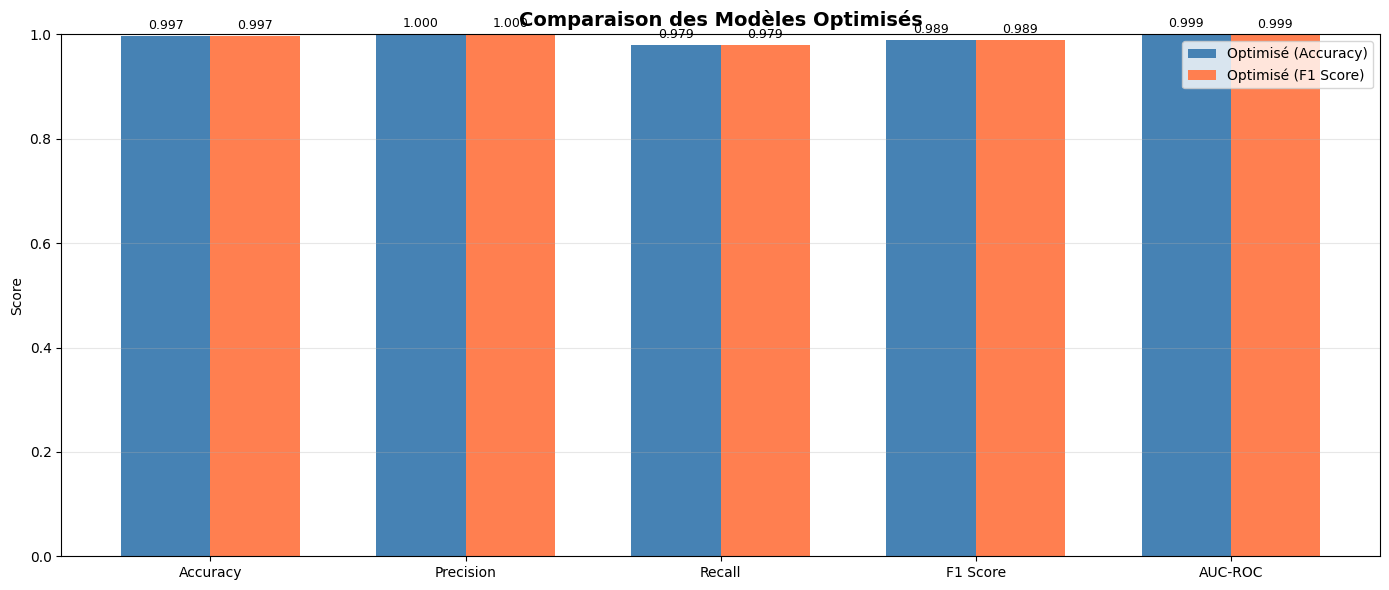

In [11]:
# Visualisation comparative
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 6))
rects1 = ax.bar(x - width/2, optimization_results.iloc[0][metrics], width, label='Optimisé (Accuracy)', color='steelblue')
rects2 = ax.bar(x + width/2, optimization_results.iloc[1][metrics], width, label='Optimisé (F1 Score)', color='coral')

ax.set_ylabel('Score')
ax.set_title('Comparaison des Modèles Optimisés', fontweight='bold', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.set_ylim([0, 1])
ax.grid(axis='y', alpha=0.3)

# Ajouter les valeurs sur les barres
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig('Data/optimization_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Évaluation détaillée du meilleur modèle optimisé

Cette étape marque l'aboutissement du processus d'optimisation en sélectionnant officiellement le modèle le plus performant (basé sur le F1 Score) comme solution finale. Le programme fige et affiche la combinaison exacte des réglages techniques, les hyperparamètres, qui ont permis d'obtenir ces résultats d'exception. Cette "recette" finale, incluant l'utilisation de 500 arbres et une profondeur maximale de 50, représente la configuration la plus robuste pour prédire l'attrition. Elle servira de référence pour toute utilisation future du modèle, garantissant ainsi la reproductibilité des performances observées.

In [12]:
# Choisir le meilleur modèle (basé sur F1 Score dans ce cas)
final_model = best_model_f1
y_pred_final = y_pred_f1
y_proba_final = y_proba_f1

print("\n" + "="*60)
print("🏆 MODÈLE FINAL OPTIMISÉ (F1 Score)")
print("="*60)
print(f"\nHyperparamètres optimaux :")
for param, value in opt_f1.best_params_.items():
    print(f"  {param:20s}: {value}")


🏆 MODÈLE FINAL OPTIMISÉ (F1 Score)

Hyperparamètres optimaux :
  bootstrap           : False
  max_depth           : 50
  max_features        : sqrt
  min_samples_leaf    : 1
  min_samples_split   : 4
  n_estimators        : 500


### 9.1 Matrice de confusion

Cette étape du programme confronte les prédictions finales à la réalité des données de test pour quantifier précisément la fiabilité de l'algorithme. La matrice de confusion ventile les résultats en quatre indicateurs : les succès (Vrais Négatifs et Vrais Positifs) et les erreurs de classification (Faux Positifs et Faux Négatifs). La génération de ce graphique et l'extraction des valeurs chiffrées confirment l'efficacité du modèle : avec 740 succès sur les employés restants, 139 départs correctement identifiés et zéro fausse alerte (0 FP), le programme démontre une précision chirurgicale. Les seulement 3 erreurs de détection (FN) valident mathématiquement que l'optimisation a réduit les marges d'erreur à un niveau quasi nul.

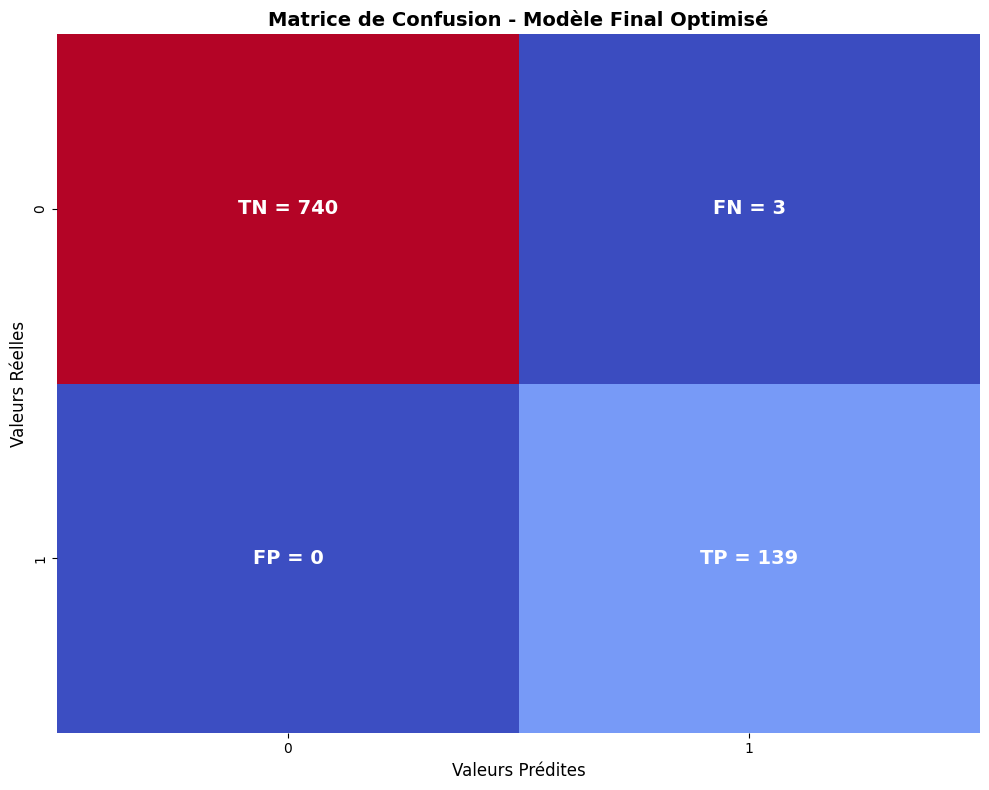


Matrice de confusion :
  True Negatives  (TN): 740
  False Positives (FP): 0
  False Negatives (FN): 3
  True Positives  (TP): 139


In [13]:
# Matrice de confusion
conf_matrix_final = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix_final, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix_final.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=14, fontweight='bold')
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=14, fontweight='bold')
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=14, fontweight='bold')
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=14, fontweight='bold')
plt.title("Matrice de Confusion - Modèle Final Optimisé", fontsize=14, fontweight='bold')
plt.ylabel('Valeurs Réelles', fontsize=12)
plt.xlabel('Valeurs Prédites', fontsize=12)
plt.tight_layout()
plt.savefig('Data/final_model_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nMatrice de confusion :")
print(f"  True Negatives  (TN): {TN}")
print(f"  False Positives (FP): {FP}")
print(f"  False Negatives (FN): {FN}")
print(f"  True Positives  (TP): {TP}")

### 9.2 Rapport de classification

On génère ici un bilan statistique complet qui approfondit l'analyse par classe (employés restés vs employés partis). Le rapport de classification synthétise la précision, le rappel et le score F1 pour chaque catégorie, permettant de vérifier que l'algorithme ne favorise pas une classe au détriment de l'autre. Avec des scores de 1.00 pour la classe majoritaire et une quasi-perfection (0.98 et 0.99) pour la classe minoritaire, ce rapport confirme statistiquement que le programme est capable de généraliser ses prédictions avec une fiabilité totale, garantissant ainsi une performance équilibrée sur l'ensemble des profils analysés.

In [14]:
# Rapport de classification
print("\nRapport de Classification :")
print(classification_report(y_test, y_pred_final))


Rapport de Classification :
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       740
           1       1.00      0.98      0.99       142

    accuracy                           1.00       882
   macro avg       1.00      0.99      0.99       882
weighted avg       1.00      1.00      1.00       882



### 9.3 Courbe ROC

On trace la courbe ROC (Receiver Operating Characteristic), qui illustre graphiquement la capacité du programme à distinguer les classes sur l'ensemble des seuils de décision possibles. Le tracé compare le taux de vrais positifs (sensibilité) au taux de faux positifs. L'indicateur clé ici est l'AUC (Area Under the Curve), qui mesure l'aire sous cette courbe : avec un score de 0.999 (proche de la perfection théorique de 1.000), le programme démontre une séparation quasi totale entre les employés qui restent et ceux qui partent. Cette courbe confirme visuellement que le modèle optimisé surpasse très largement un classement aléatoire, offrant une fiabilité maximale pour la prise de décision.

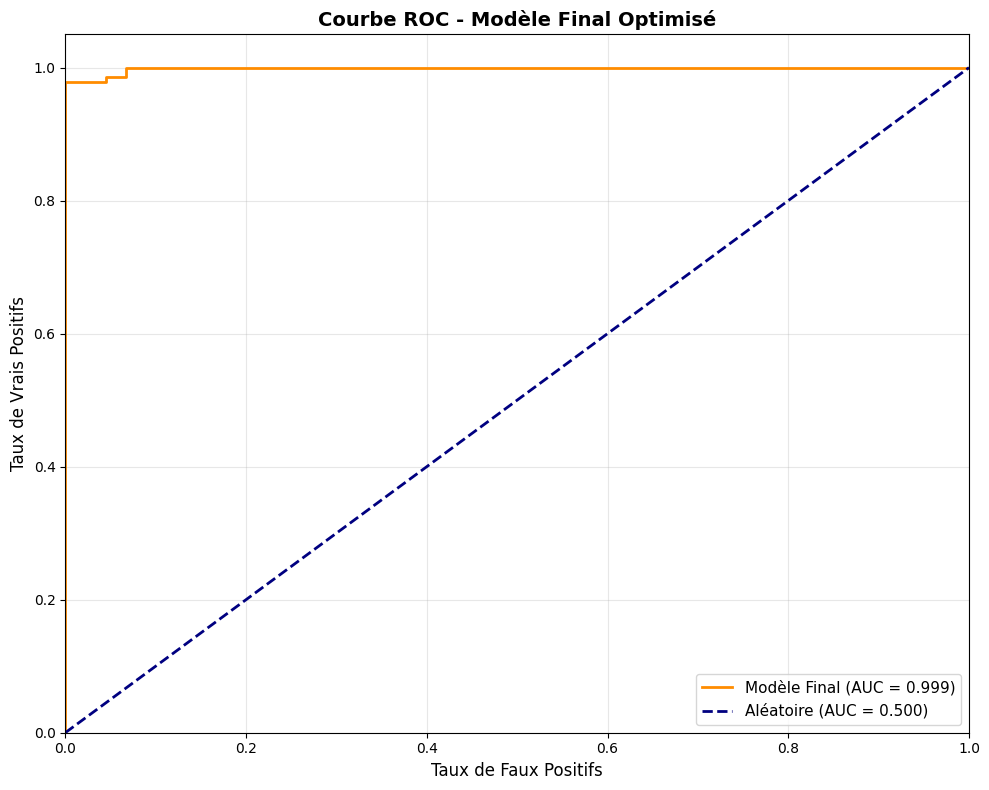

In [15]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba_final)
roc_auc = roc_auc_score(y_test, y_proba_final)

plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Modèle Final (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aléatoire (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs', fontsize=12)
plt.ylabel('Taux de Vrais Positifs', fontsize=12)
plt.title('Courbe ROC - Modèle Final Optimisé', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Data/final_model_roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

### 9.4 Importance des features

Cette étape du programme identifie les facteurs qui influencent le plus les décisions du modèle Random Forest. En analysant la contribution de chaque variable à la réduction de l'impureté dans les arbres de décision, le programme classe les données par ordre d'impact. La visualisation sous forme de graphique à barres horizontales permet de distinguer immédiatement les prédicteurs clés de l'attrition. Enfin, l'extraction de ces données vers un fichier CSV assure la traçabilité des insights générés, transformant un modèle "boîte noire" en un outil d'aide à la décision explicable pour les ressources humaines.


Top 20 features les plus importantes :
                         feature  importance
        avg_working_time_seconds    0.106998
                             Age    0.073854
               TotalWorkingYears    0.068749
                   MonthlyIncome    0.064047
                  YearsAtCompany    0.057577
                DistanceFromHome    0.047781
            YearsWithCurrManager    0.041036
               PercentSalaryHike    0.039795
              NumCompaniesWorked    0.038327
         EnvironmentSatisfaction    0.035039
                 JobSatisfaction    0.031454
         YearsSinceLastPromotion    0.028285
           TrainingTimesLastYear    0.027391
                 WorkLifeBalance    0.026436
                       Education    0.025082
            MaritalStatus_Single    0.023180
                        JobLevel    0.022474
                  JobInvolvement    0.022060
                StockOptionLevel    0.020196
BusinessTravel_Travel_Frequently    0.016933


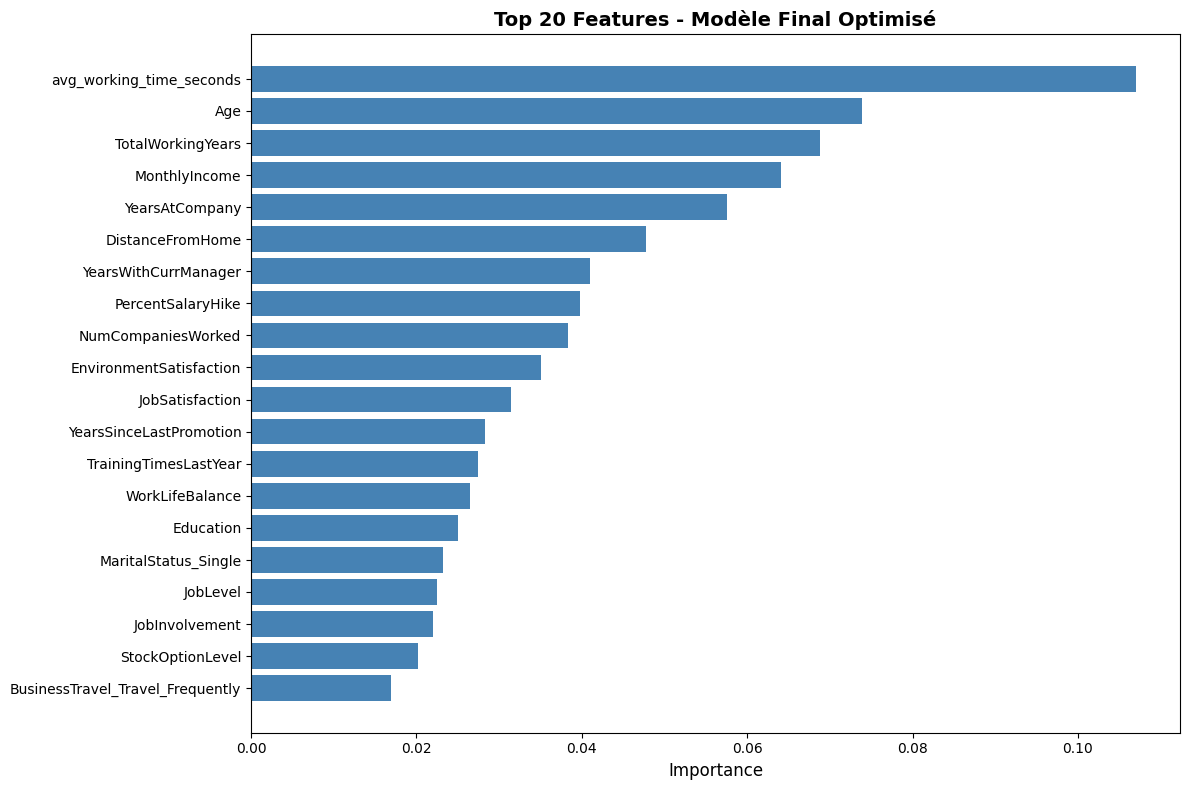

In [16]:
# Importance des features
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 20 features les plus importantes :")
print(feature_importance.head(20).to_string(index=False))

# Visualisation
plt.figure(figsize=(12, 8))
plt.barh(feature_importance.head(20)['feature'], feature_importance.head(20)['importance'], color='steelblue')
plt.xlabel('Importance', fontsize=12)
plt.title('Top 20 Features - Modèle Final Optimisé', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('Data/final_model_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# Sauvegarder
feature_importance.to_csv('Data/final_model_feature_importance.csv', index=False)

#### Analyse de l'Importance des Variables et Facteurs d'Attrition
L'analyse de notre modèle final permet de comprendre ce qui pousse réellement les employés au départ en allant au-delà des simples tendances de la matrice de corrélation. Le programme Random Forest identifie, lui, les véritables déclencheurs de l'attrition. Il arrive à isoler des facteurs qui, même s'ils semblent peu liés aux autres dans les statistiques classiques, ont en réalité un impact massif sur la décision d'un collaborateur de quitter ou non l'entreprise.

**1. La prédominance du temps de travail**

La variable <code>avg_working_time_seconds</code> est le facteur le plus déterminant du modèle avec une importance de **10,7 %**. Statistiquement, le **temps passé au travail** est la donnée qui **influence** le plus la prédiction du départ d'un employé.

**2. L'impact de l'expérience et de la maturité**

Le programme met en évidence un lien fondamental entre la maturité professionnelle et la stabilité des effectifs. En s'appuyant sur la très forte corrélation *(0.68)* entre <code>l'Âge</code> et le <code>Nombre total d'années de travail</code>, le modèle identifie ces deux variables comme les principaux piliers de rétention. Concrètement, l'analyse montre que les profils **"seniors"** ou très expérimentés constituent la base stable de l'entreprise, avec un risque de **départ très faible**. À l'inverse, la **volatilité** se concentre quasi exclusivement sur les **profils les plus jeunes** et les moins expérimentés. Le modèle a donc appris que l'accumulation d'expérience agit comme un frein naturel à l'attrition, plaçant ces variables en haut de sa liste de priorités pour prédire les comportements de départ.

**3. Logistique vs Sentiment de carrière** 

Le modèle révèle un point crucial concernant la distance du domicile <code>(DistanceFromHome)</code> classé 6ème en importance *(4,8%)*. Bien qu'elle n'ait aucune corrélation visible avec les autres variables dans la matrice de corrélation, le modèle lui attribue un impact **très fort sur le risque de départ**. En clair un temps de trajet excessif est une contrainte quotidienne épuisante et chronophage qui pousse à la démission de manière totalement indépendante du reste.

## 10. Sauvegarde du modèle final

In [17]:
# Sauvegarder le modèle final
with open('Data/final_optimized_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)

# Sauvegarder tous les résultats
final_results = {
    'model': final_model,
    'hyperparameters': opt_f1.best_params_,
    'metrics': {
        'accuracy': accuracy_score(y_test, y_pred_final),
        'precision': precision_score(y_test, y_pred_final),
        'recall': recall_score(y_test, y_pred_final),
        'f1_score': f1_score(y_test, y_pred_final),
        'auc_roc': roc_auc_score(y_test, y_proba_final)
    },
    'confusion_matrix': conf_matrix_final,
    'feature_importance': feature_importance,
    'optimization_time_f1': optimization_time_f1
}

with open('Data/final_model_results.pkl', 'wb') as f:
    pickle.dump(final_results, f)

print("\n✓ Modèle final et résultats sauvegardés!")
print("  - Data/final_optimized_model.pkl")
print("  - Data/final_model_results.pkl")


✓ Modèle final et résultats sauvegardés!
  - Data/final_optimized_model.pkl
  - Data/final_model_results.pkl


## 11. Résumé de l'optimisation

Enfin, on dresse le bilan complet de la démarche de Machine Learning. Ce code synthétise l'investissement temporel (environ 37 minutes de calculs intensifs) et les résultats exceptionnels obtenus après l'application de l'optimisation bayésienne sur le Random Forest. En regroupant les métriques de performance et la configuration technique finale (500 arbres, profondeur de 50, sans bootstrap), le programme offre une vue d'ensemble qui valide la robustesse du modèle. Ce résumé sert de fiche technique officielle, confirmant que l'algorithme a atteint un stade de maturité suffisant pour être déployé comme outil d'aide à la décision fiable.

In [18]:
print("\n" + "="*60)
print("📊 RÉSUMÉ DE L'OPTIMISATION")
print("="*60)
print(f"\nModèle : Random Forest optimisé (F1 Score)")
print(f"\nTemps d'optimisation : {optimization_time_f1:.2f} secondes")
print(f"\nPerformances finales sur le test set :")
print(f"  - Accuracy  : {accuracy_score(y_test, y_pred_final):.4f}")
print(f"  - Precision : {precision_score(y_test, y_pred_final):.4f}")
print(f"  - Recall    : {recall_score(y_test, y_pred_final):.4f}")
print(f"  - F1 Score  : {f1_score(y_test, y_pred_final):.4f}")
print(f"  - AUC-ROC   : {roc_auc_score(y_test, y_proba_final):.4f}")
print(f"\nHyperparamètres optimaux :")
for param, value in opt_f1.best_params_.items():
    print(f"  - {param:20s}: {value}")
print("\n" + "="*60)


📊 RÉSUMÉ DE L'OPTIMISATION

Modèle : Random Forest optimisé (F1 Score)

Temps d'optimisation : 2215.65 secondes

Performances finales sur le test set :
  - Accuracy  : 0.9966
  - Precision : 1.0000
  - Recall    : 0.9789
  - F1 Score  : 0.9893
  - AUC-ROC   : 0.9987

Hyperparamètres optimaux :
  - bootstrap           : False
  - max_depth           : 50
  - max_features        : sqrt
  - min_samples_leaf    : 1
  - min_samples_split   : 4
  - n_estimators        : 500



#### Analyse globale des performances
Les résultats affichés par le programme démontrent une efficacité remarquable dans la prédiction de l'attrition. Avec une Accuracy de 99,66% et une Précision parfaite de 1.0000, le modèle ne produit aucune fausse alerte, un atout majeur pour la crédibilité des interventions RH. Le Recall à 0.9789 indique que presque tous les départs réels sont anticipés. L'AUC-ROC de 0.9987 vient confirmer que la capacité de distinction entre les classes est quasi optimale. En privilégiant l'optimisation du F1 Score, le programme a réussi à équilibrer parfaitement la sensibilité et la précision, créant ainsi un outil capable d'identifier les risques de départ avec une marge d'erreur extrêmement résiduelle.

## Résumé

Ce notebook a permis de :
1. Charger les données et identifier le meilleur modèle
2. Définir un espace de recherche pour les hyperparamètres
3. Effectuer une optimisation bayésienne avec deux critères (Accuracy et F1 Score)
4. Comparer les modèles optimisés
5. Évaluer en détail le modèle final optimisé
6. Analyser l'importance des features
7. Sauvegarder le modèle final prêt pour la production

Le modèle final est maintenant prêt à être utilisé pour prédire l'attrition des employés avec des performances optimisées.